In [50]:
import matplotlib.pyplot as plt
import numpy as np
import pathlib 

import mne
from mne.datasets import somato # useless, written just to represent an example

Set parameters

In [51]:
subject = "Julia"
data_path = pathlib.Path(f"/Users/alexmedvedev/Desktop/Vishka/exp/") # replace with your data_path

# Setup for reading the raw data
raw = mne.io.read_raw_brainvision(data_path / f'{subject}.vhdr', preload = True)
# crop and resample just to reduce computation time
raw.crop(120, 360).load_data().resample(200)
events, ids = mne.events_from_annotations(raw)

montage = mne.channels.make_standard_montage("standard_1020")
raw.set_montage(montage)

# picks MEG gradiometers
picks = mne.pick_types(raw.info, meg=False, eeg=True, eog=False, stim=False)

# Construct Epochs
five_id = {'5-6': 5 or 51}
five_events = mne.pick_events(events, include = [5, 51])
tmin, tmax = -0.5, 1.0
baseline = (-0.5, 0)
epochs = mne.Epochs(
    raw,
    five_events,
    five_id,
    tmin,
    tmax,
    picks=picks,
    baseline=baseline,
    preload=True,
    reject_by_annotation=True
)

Extracting parameters from /Users/alexmedvedev/Desktop/Vishka/exp/Julia.vhdr...
Setting channel info structure...
Reading 0 ... 1049499  =      0.000 ...  2098.998 secs...
Used Annotations descriptions: ['Stimulus/S  5', 'Stimulus/S  7', 'Stimulus/S  9', 'Stimulus/S 11', 'Stimulus/S 91', 'Stimulus/S111']
Not setting metadata
4 matching events found
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 4 events and 301 original time points ...
0 bad epochs dropped


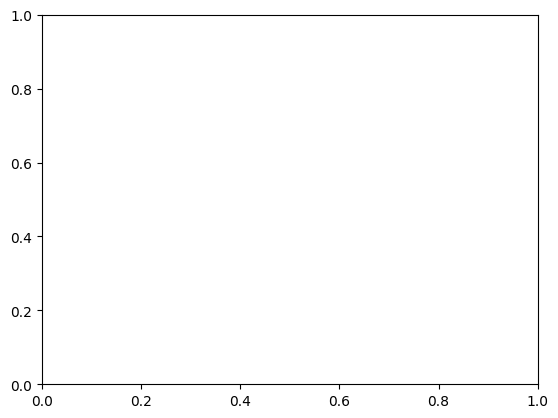

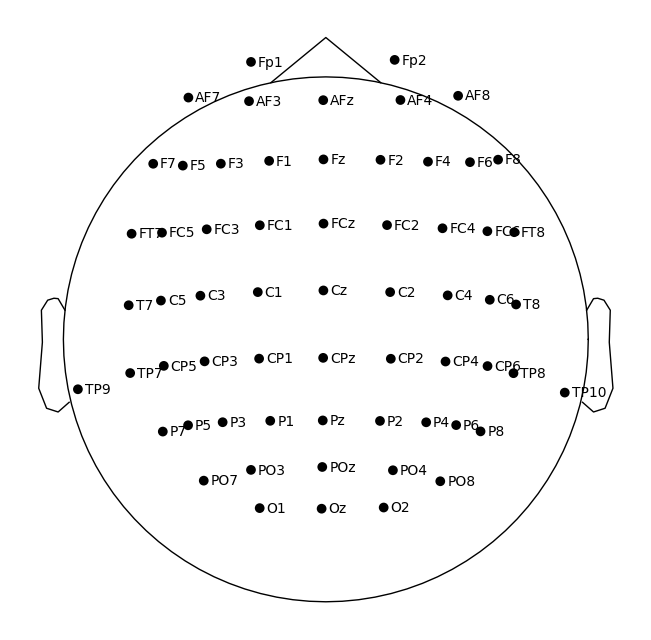

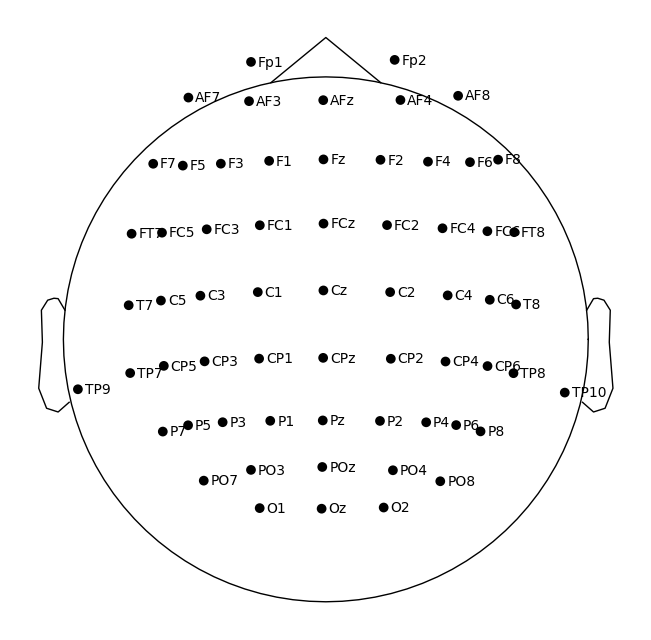

In [97]:
raw.plot_sensors(show_names = True) #What if we would like to see the names

We start by exploring the frequency content of our epochs.

Let’s first check out all channel types by averaging across epochs.

    Using multitaper spectrum estimation with 7 DPSS windows
Plotting power spectral density (dB=True).
Averaging across epochs...


/Users/alexmedvedev/Library/Python/3.11/lib/python/site-packages/mne/viz/utils.py:167: UserWarning: Matplotlib is currently using module://matplotlib_inline.backend_inline, which is a non-GUI backend, so cannot show the figure.
  (fig or plt).show(**kwargs)


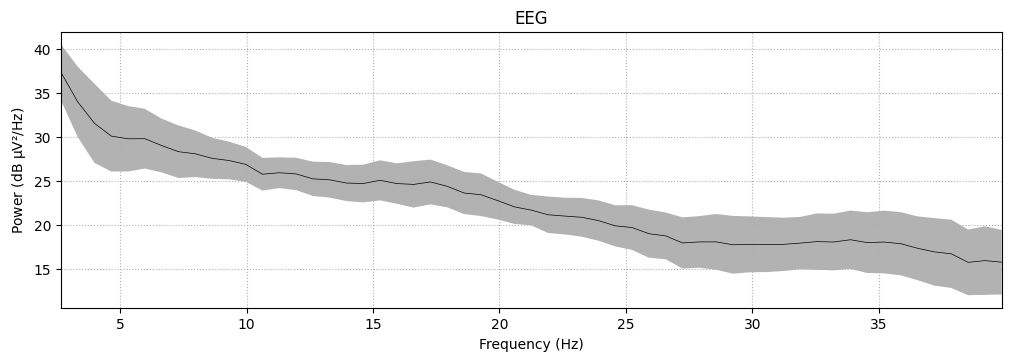

In [52]:
epochs.compute_psd(fmin=2.0, fmax=40.0).plot(
    average=True, amplitude=False, picks="data", exclude="bads"
)

Now, let’s take a look at the spatial distributions of the PSD, averaged across epochs and frequency bands.

    Using multitaper spectrum estimation with 7 DPSS windows


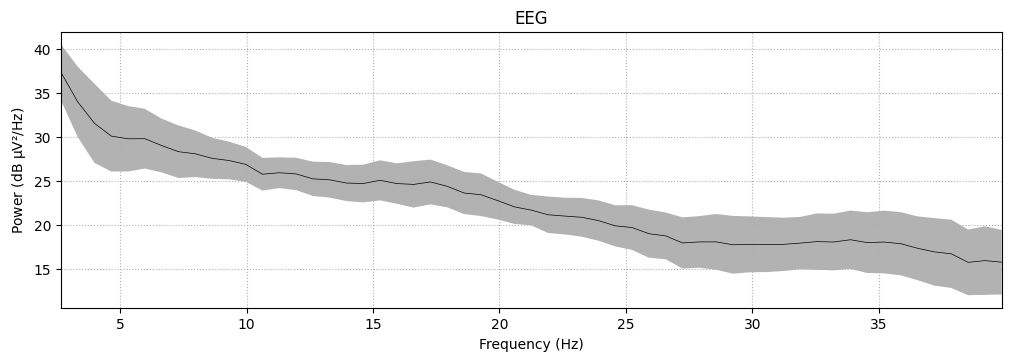

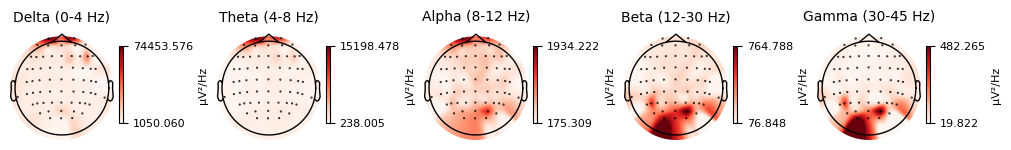

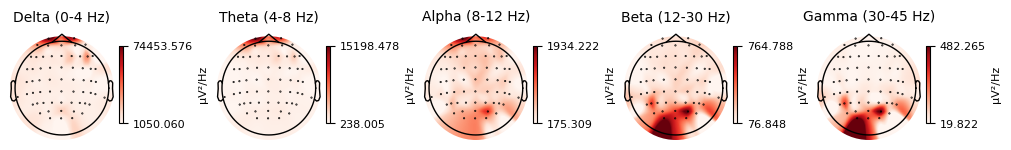

In [53]:
epochs.compute_psd().plot_topomap(ch_type="eeg", normalize=False, contours=0)

Alternatively, you can also create PSDs from Epochs methods directly. (even though it seems pretty useless)

    Using multitaper spectrum estimation with 7 DPSS windows


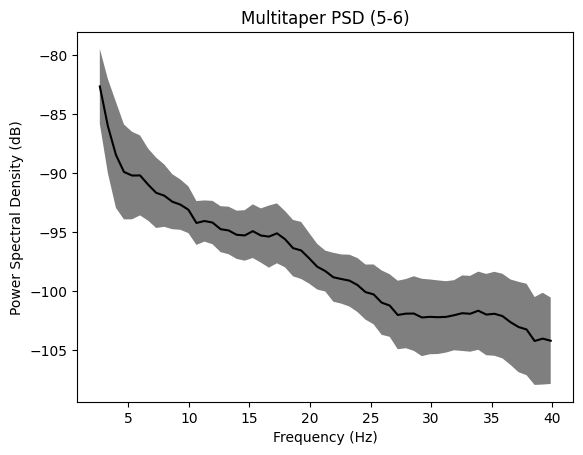

In [55]:
_, ax = plt.subplots()
spectrum = epochs.compute_psd(fmin=2.0, fmax=40.0, tmax=3.0, n_jobs=None)
# average across epochs first
mean_spectrum = spectrum.average()
psds, freqs = mean_spectrum.get_data(return_freqs=True)
# then convert to dB and take mean & standard deviation across channels
psds = 10 * np.log10(psds)
psds_mean = psds.mean(axis=0)
psds_std = psds.std(axis=0)

ax.plot(freqs, psds_mean, color="k")
ax.fill_between(
    freqs,
    psds_mean - psds_std,
    psds_mean + psds_std,
    color="k",
    alpha=0.5,
    edgecolor="none",
)
ax.set(
    title="Multitaper PSD (5-6)",
    xlabel="Frequency (Hz)",
    ylabel="Power Spectral Density (dB)",
)
plt.show()

Notably, mne.Epochs.compute_psd() supports the keyword argument average, which specifies how to estimate the PSD based on the individual windowed segments. The default is average='mean', which simply calculates the arithmetic mean across segments. Specifying average='median', in contrast, returns the PSD based on the median of the segments (corrected for bias relative to the mean), which is a more robust measure.

In [99]:
# Я ИСКРЕННЕ ПЫТАЛСЯ ЭТО СДЕЛАТЬ, НЕ ПОЛУЧИЛОСЬ

# Estimate PSDs based on "mean" and "median" averaging for comparison.
kwargs = dict(fmin=2, fmax=40, n_jobs=None)
psds_welch_mean, freqs_mean = epochs.compute_psd(
    "welch", average="mean", **kwargs
).get_data(return_freqs=True)
psds_welch_median, freqs_median = epochs.compute_psd(
    "welch", average="median", **kwargs
).get_data(return_freqs=True)

# Convert power to dB scale.
psds_welch_mean = 10 * np.log10(psds_welch_mean)
psds_welch_median = 10 * np.log10(psds_welch_median)

ep_av = epochs.compute_psd(fmin=2.0, fmax=40.0, tmax=3.0, n_jobs=None).average()
ch_idx = ['AF7', 'Fp1', 'AF3']

for i in ch_idx:
    _, ax = plt.subplots()
    ax.plot(
    freqs_mean,
    psds_welch_mean[ep_av, i, :],
    color="k",
    ls="-",
    label="mean of segments",
    )
    ax.plot(
    freqs_median,
    psds_welch_median[ep_av, i, :],
    color="k",
    ls="--",
    label="median of segments",
    )

    ax.set(
    title=f"Welch PSD Epoch {i})",
    xlabel="Frequency (Hz)",
    ylabel="Power Spectral Density (dB)",
    )
    ax.legend(loc="upper right")

Effective window size : 1.505 (s)
Effective window size : 1.505 (s)
    Using multitaper spectrum estimation with 7 DPSS windows


IndexError: only integers, slices (`:`), ellipsis (`...`), numpy.newaxis (`None`) and integer or boolean arrays are valid indices

We now compute time-frequency representations (TFRs) from our Epochs. We’ll look at power and inter-trial coherence (ITC).

To this we’ll use the function mne.time_frequency.tfr_morlet() but you can also use mne.time_frequency.tfr_multitaper() or mne.time_frequency.tfr_stockwell().

define frequencies of interest (log-spaced)

In [75]:
freqs = np.logspace(*np.log10([1, 44]), num=8)
n_cycles = freqs / 2.0  # different number of cycle per frequency
power, itc = epochs.compute_tfr(
    method="morlet",
    freqs=freqs,
    n_cycles=n_cycles,
    average=True,
    return_itc=True,
    decim=3,
)

[Parallel(n_jobs=1)]: Done  17 tasks      | elapsed:    0.0s


Inspect power

Applying baseline correction (mode: logratio)


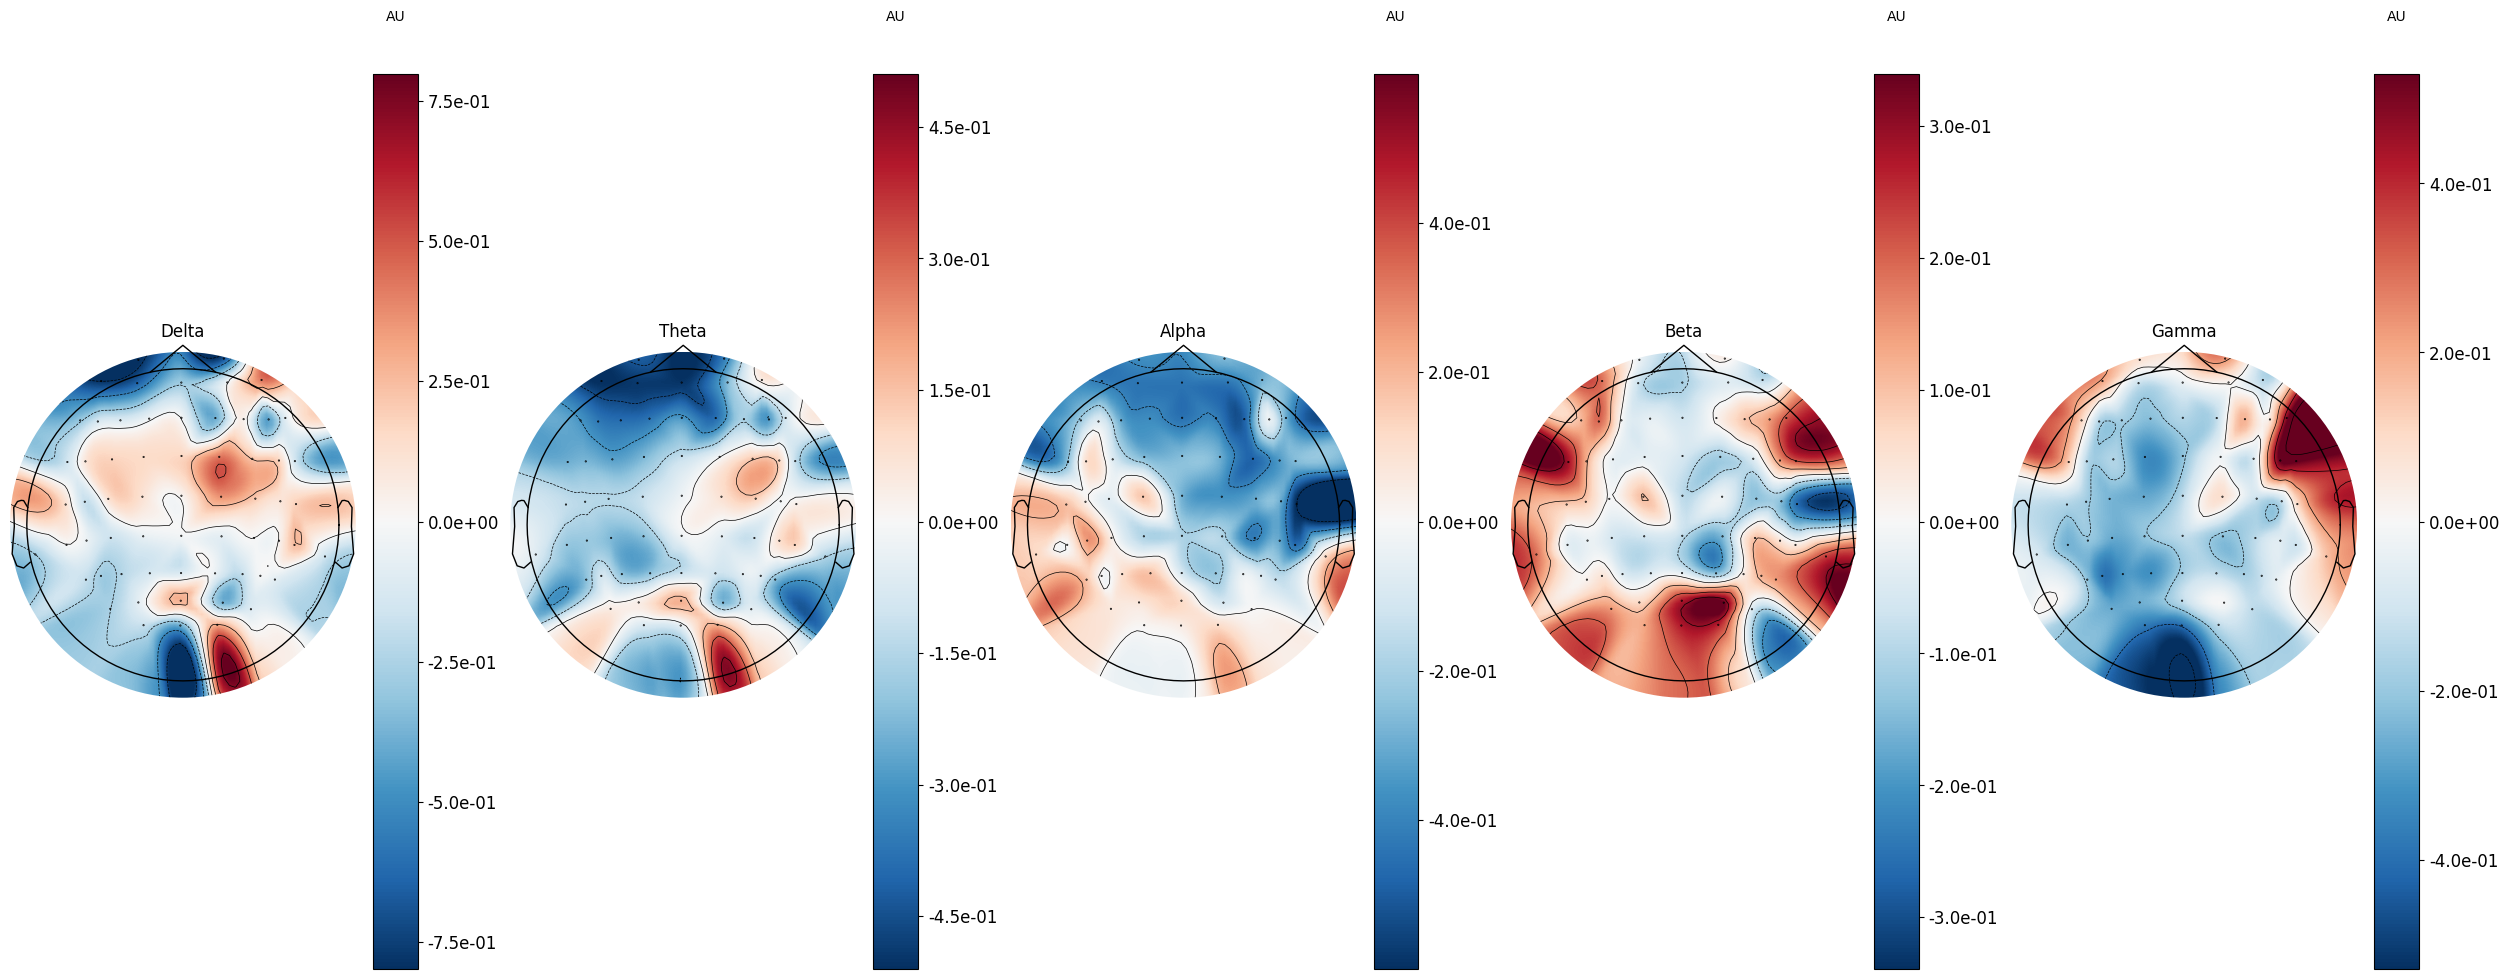

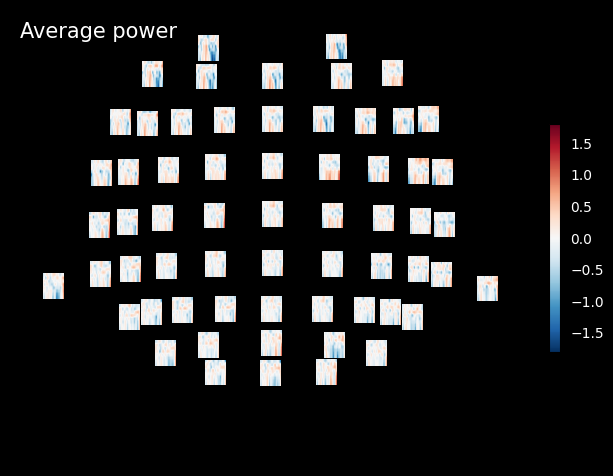

Applying baseline correction (mode: logratio)


/Users/alexmedvedev/Library/Python/3.11/lib/python/site-packages/mne/time_frequency/tfr.py:2050: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  figs = [plt.figure(layout="constrained") for _ in range(data.shape[0])]


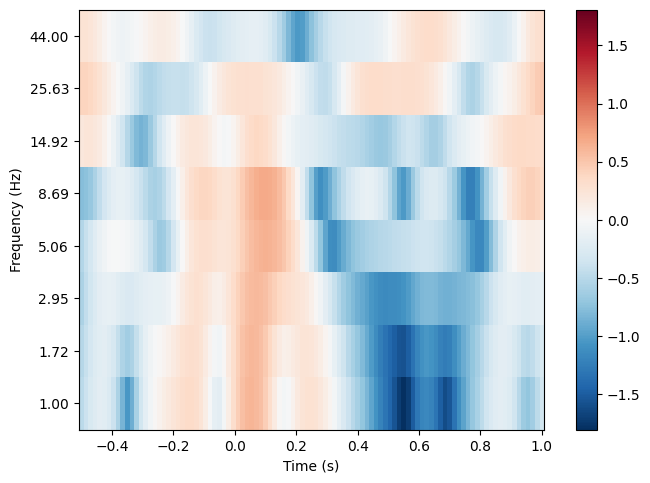

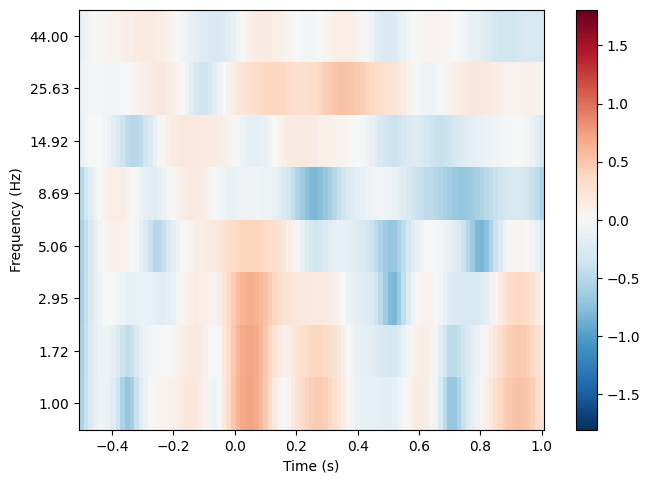

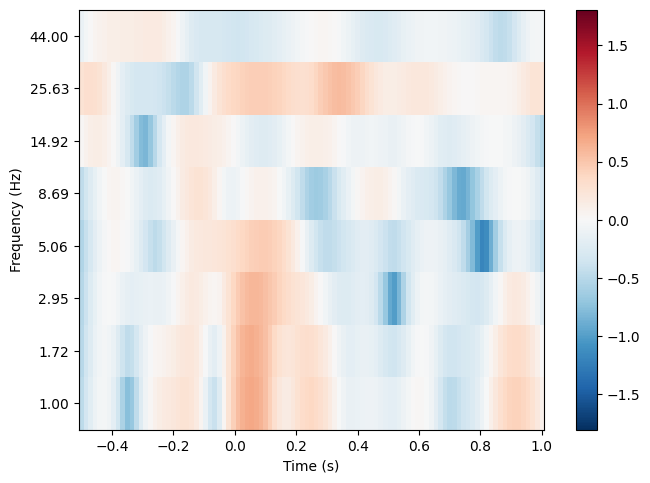

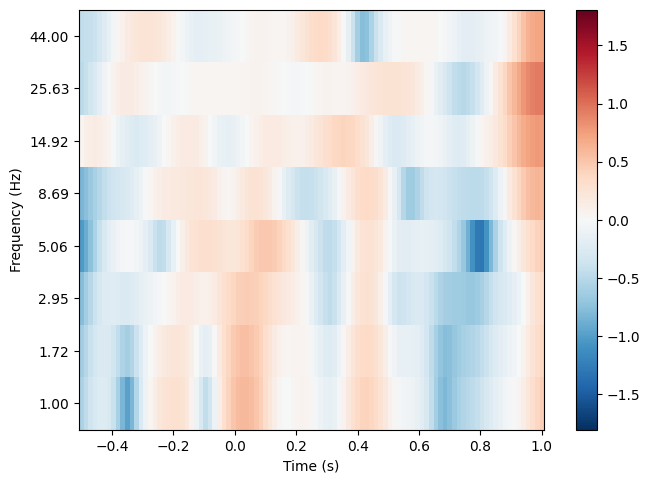

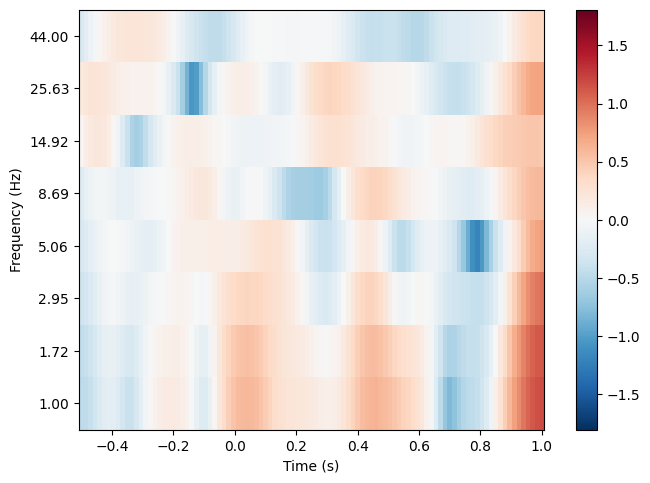

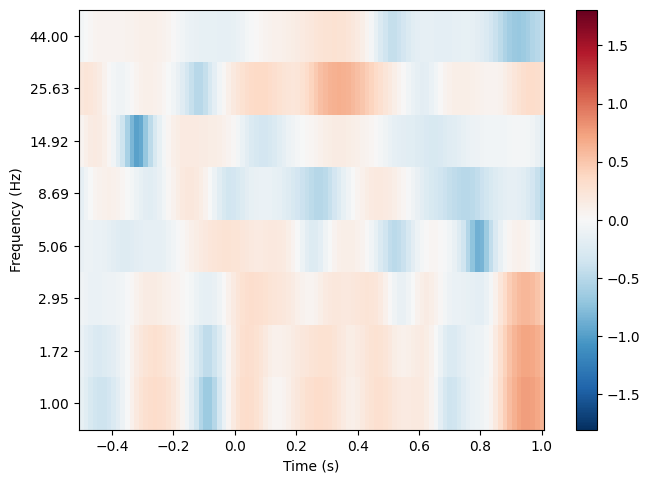

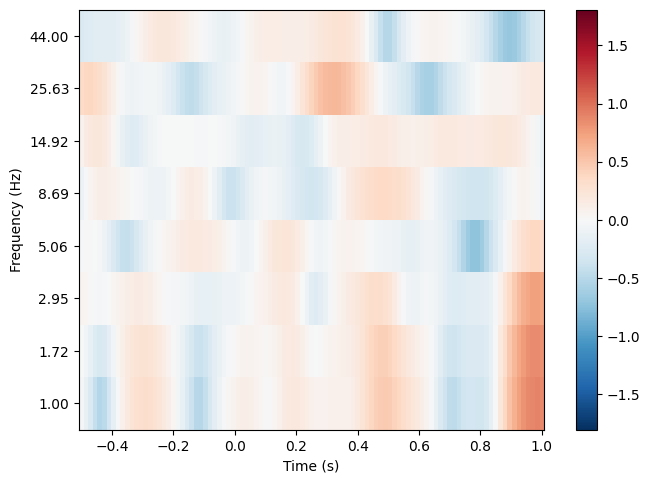

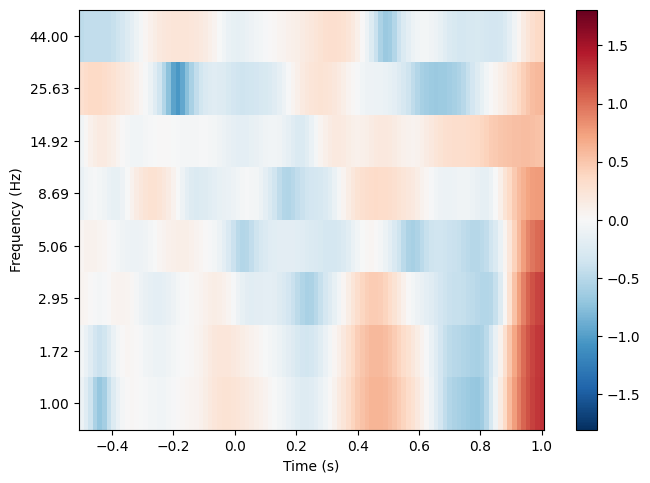

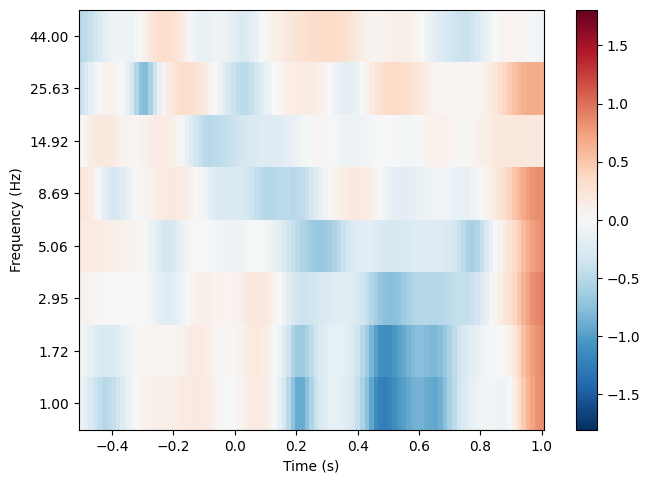

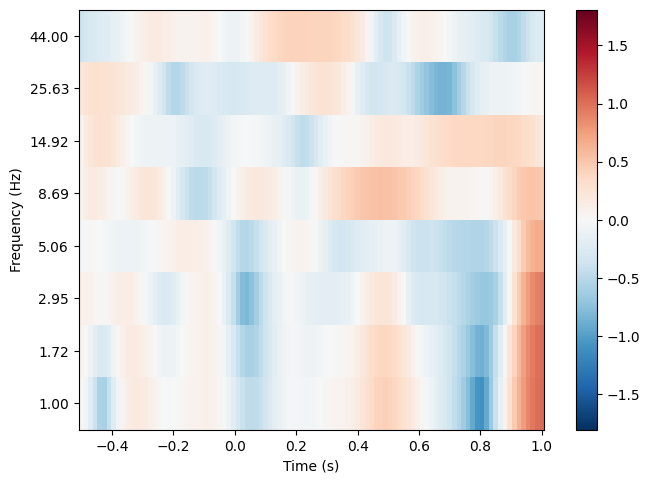

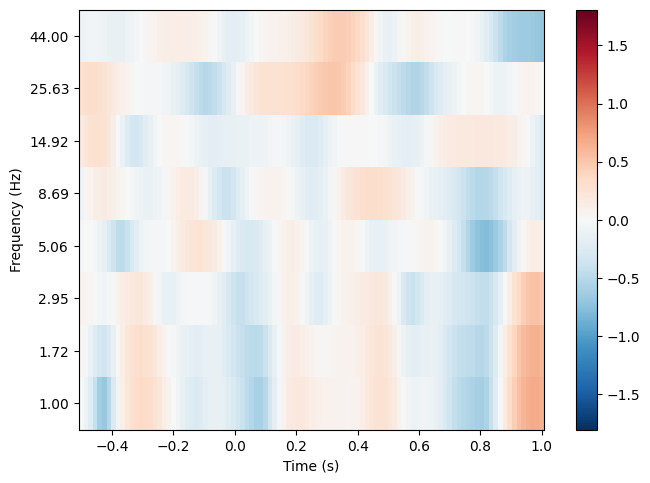

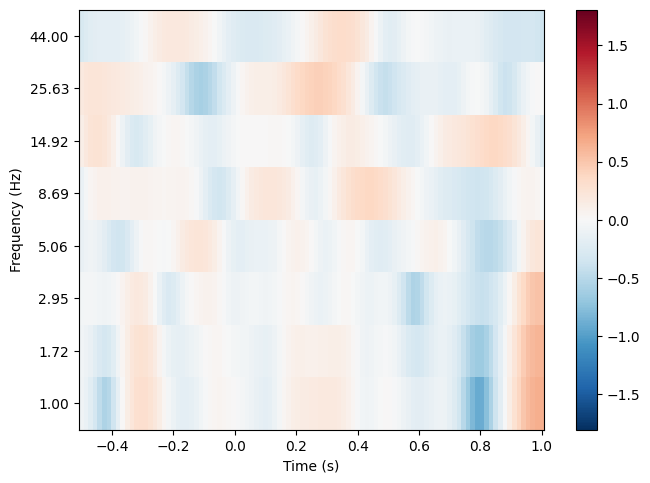

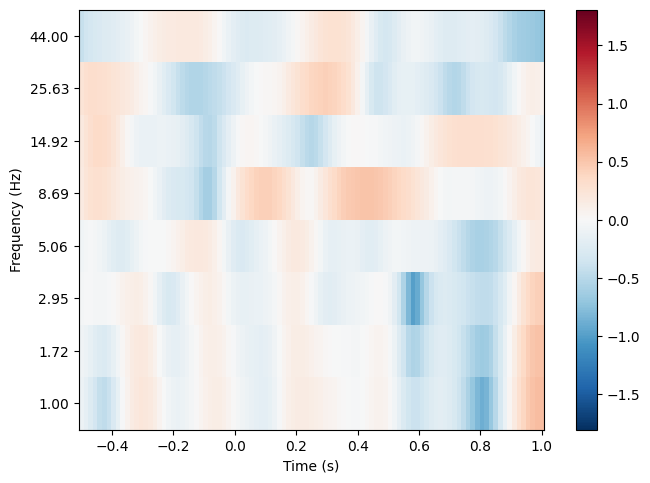

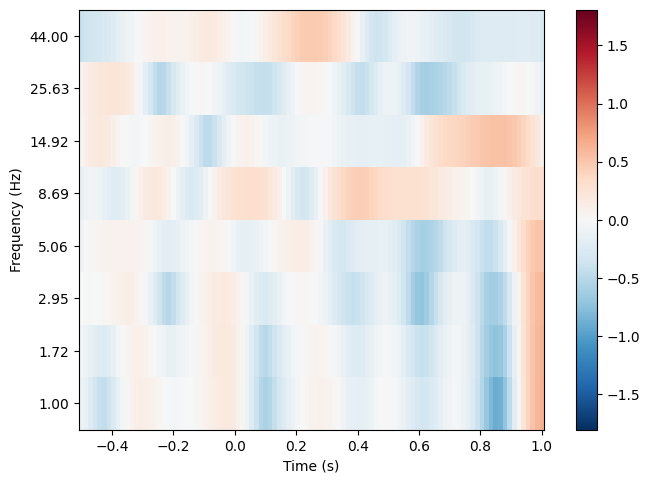

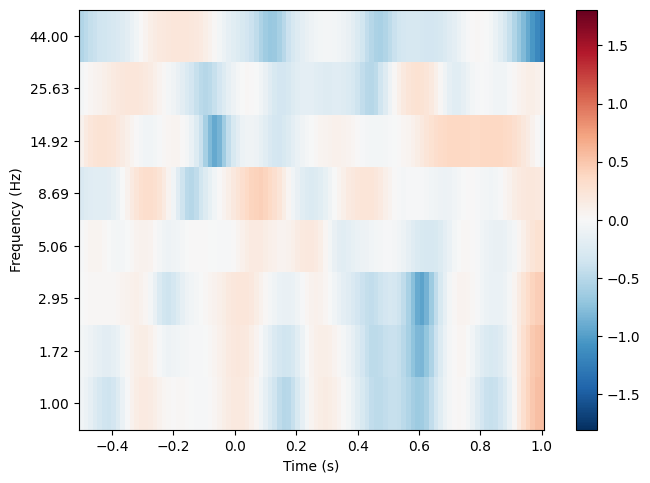

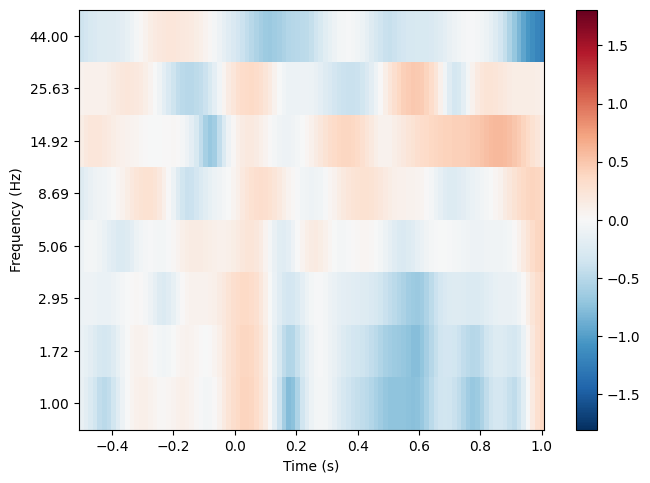

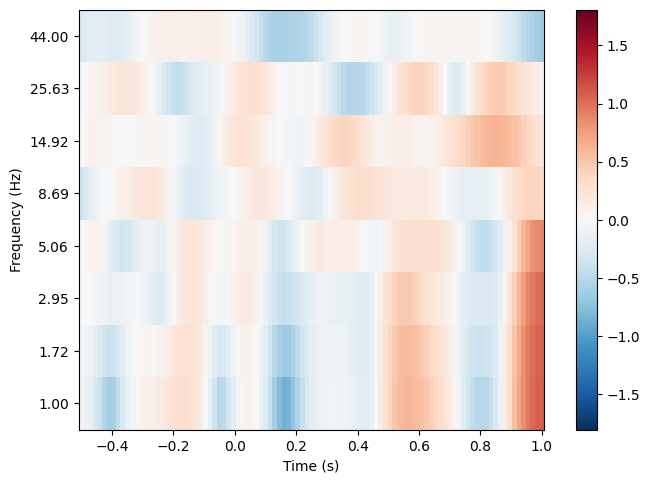

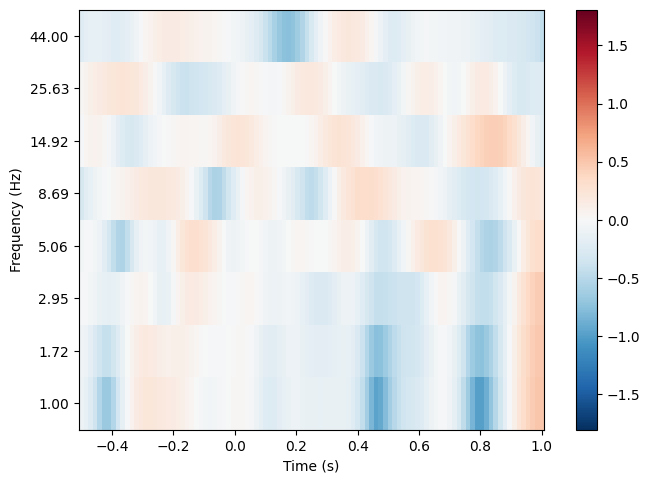

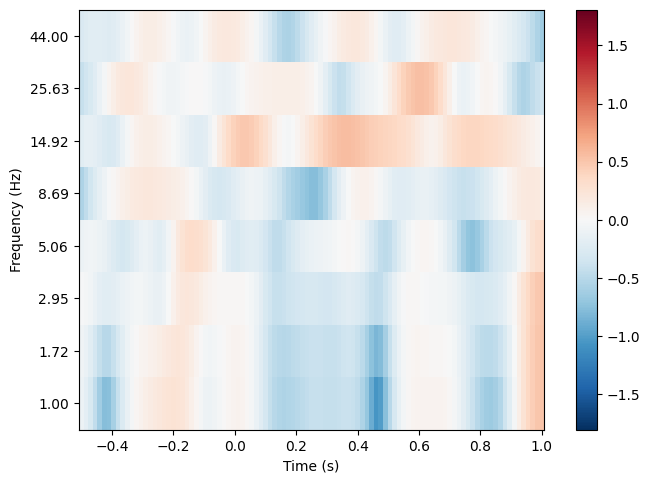

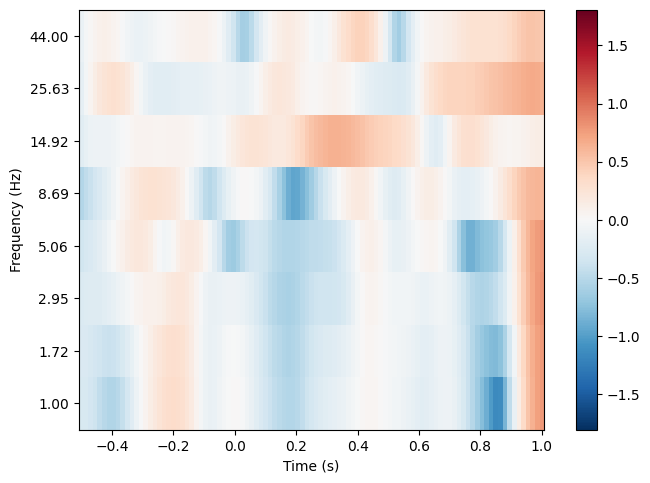

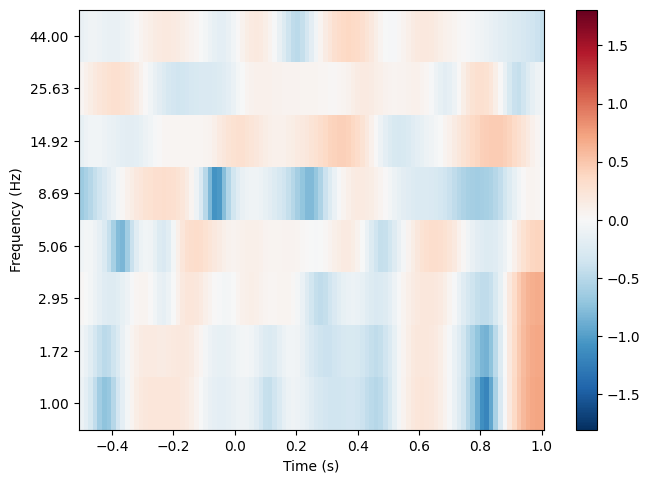

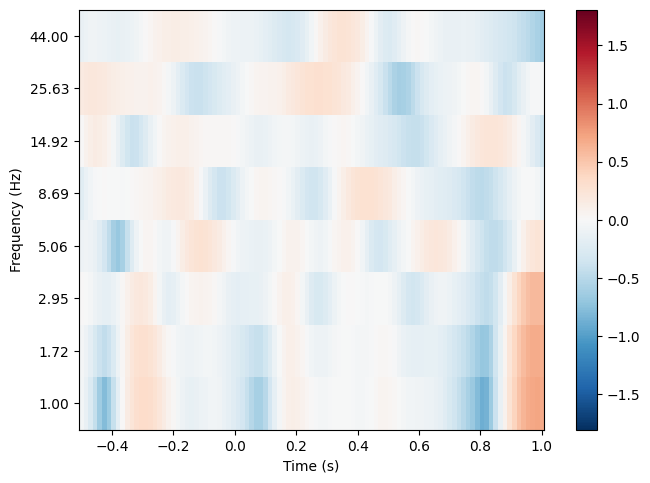

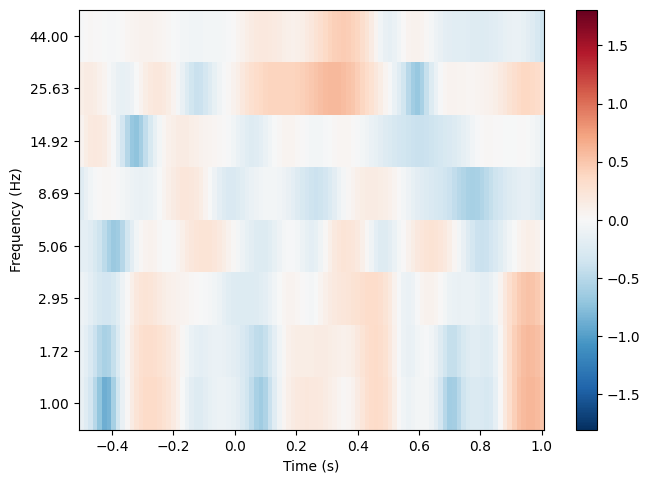

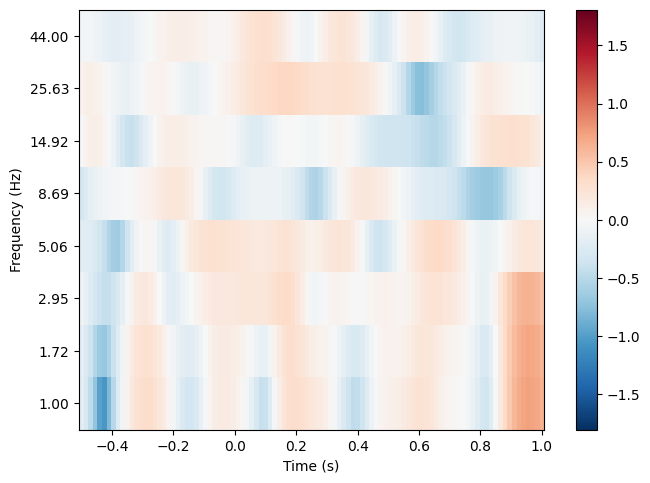

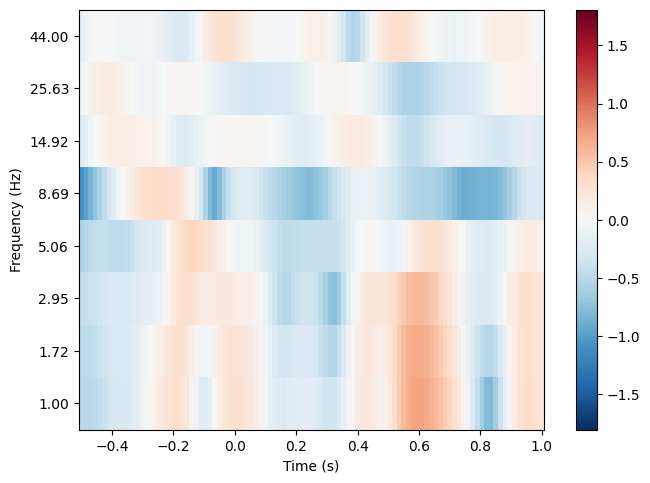

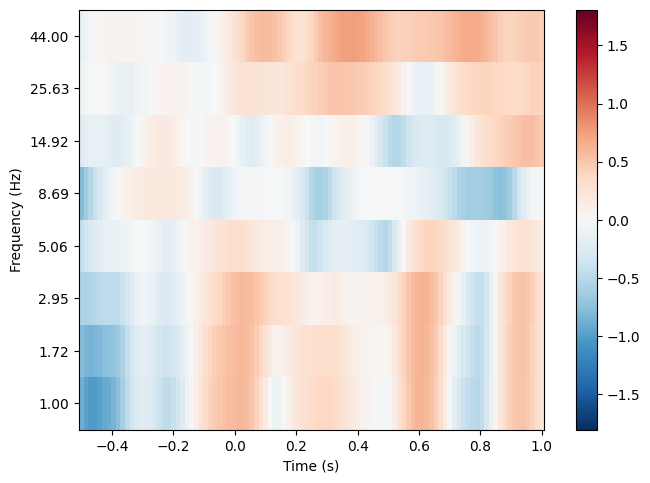

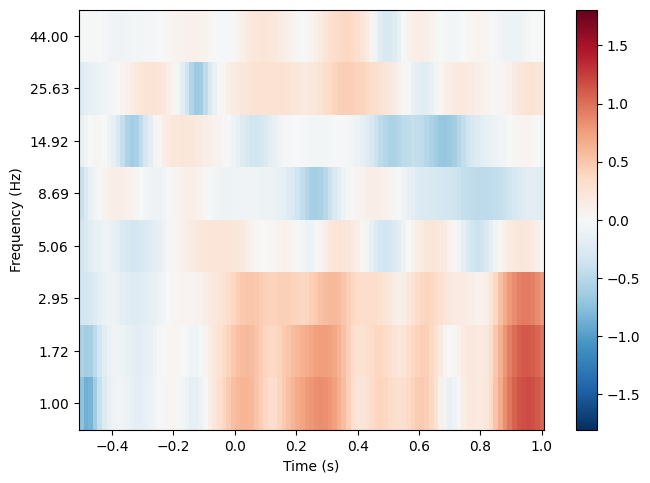

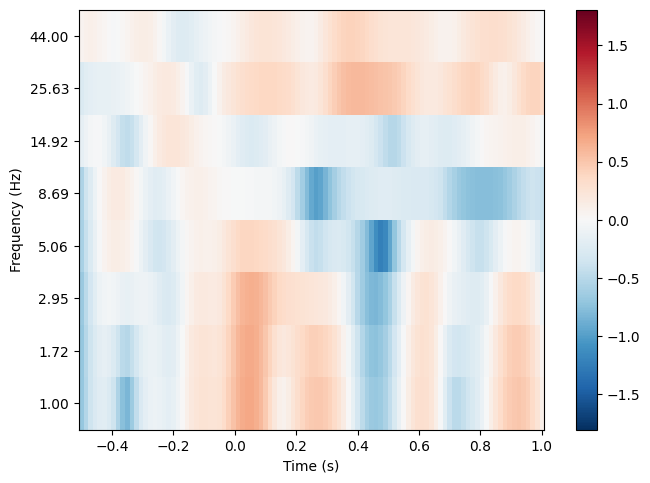

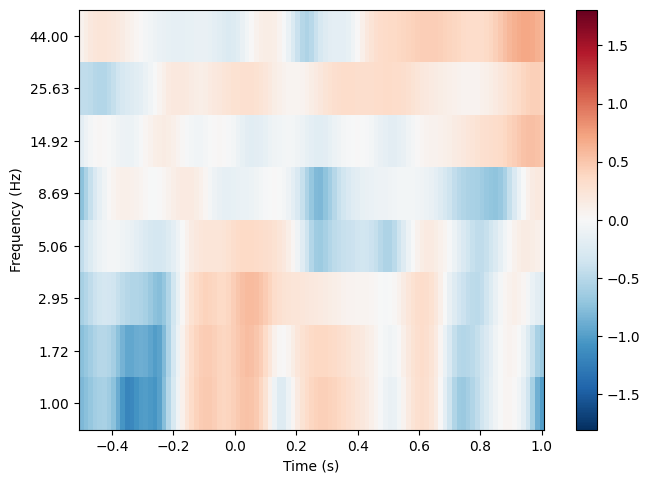

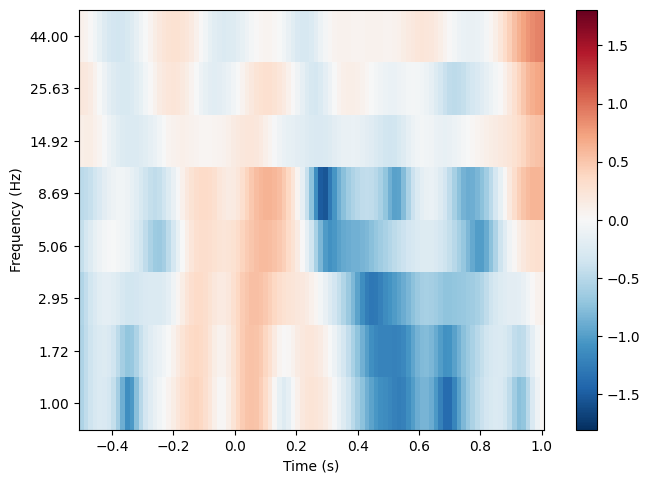

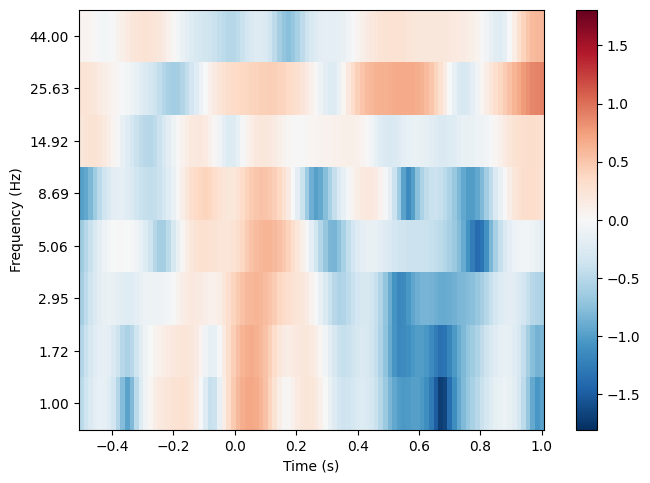

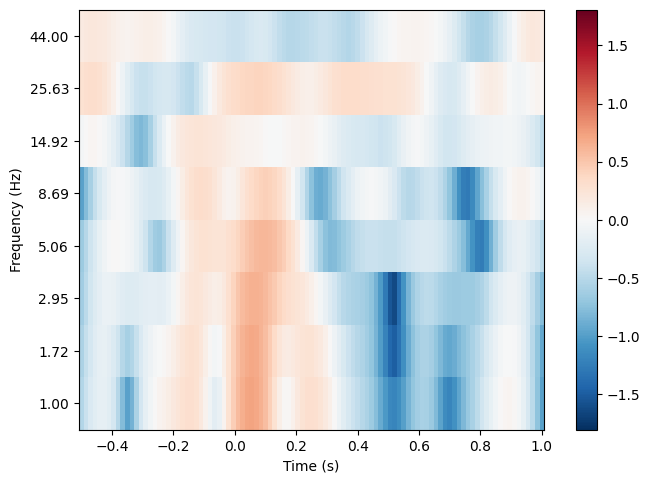

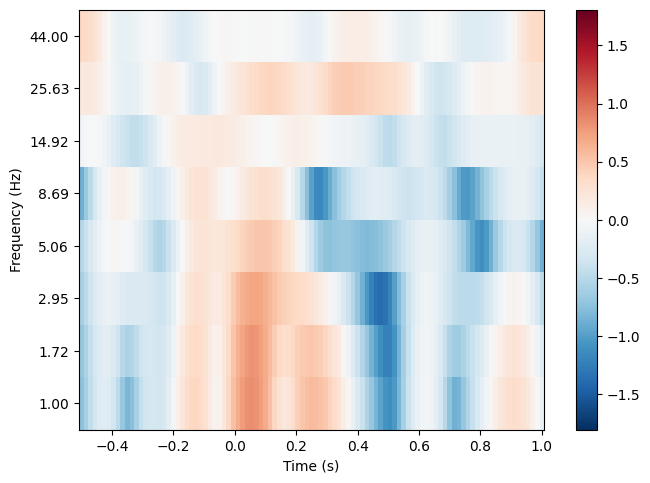

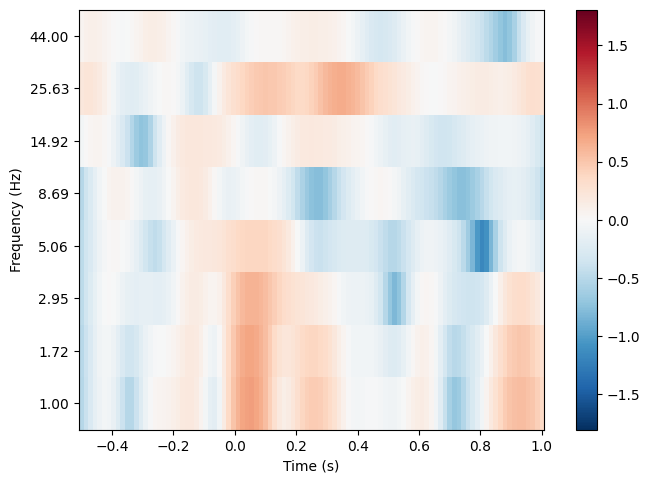

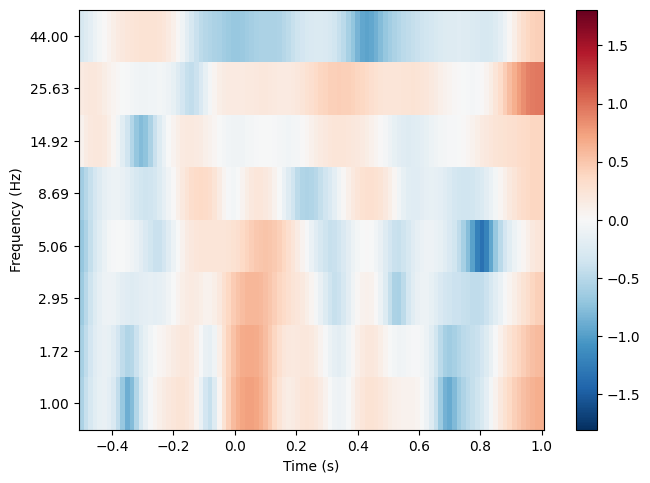

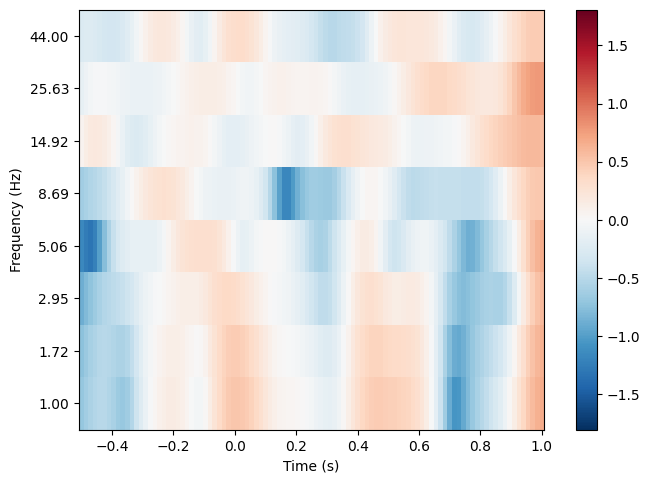

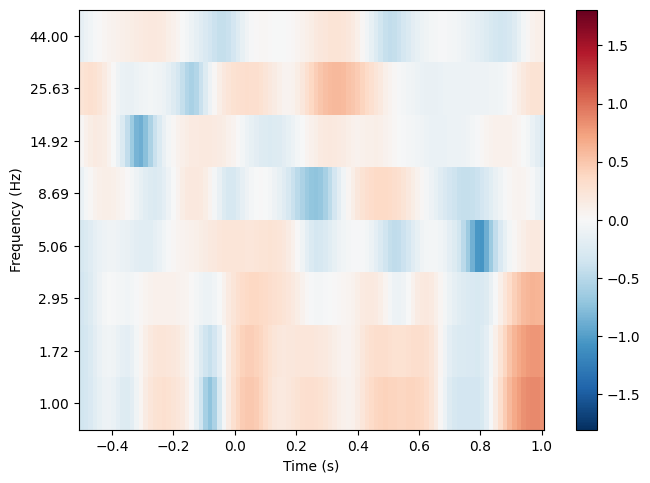

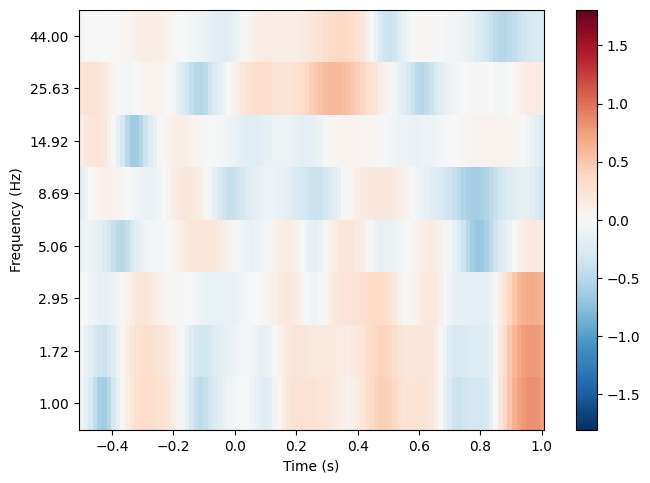

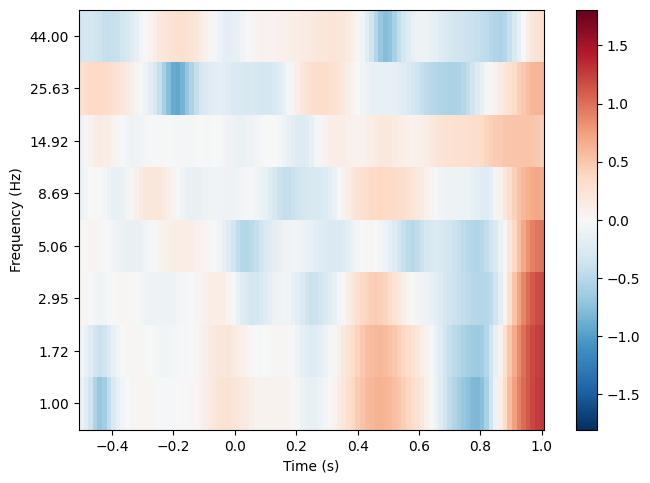

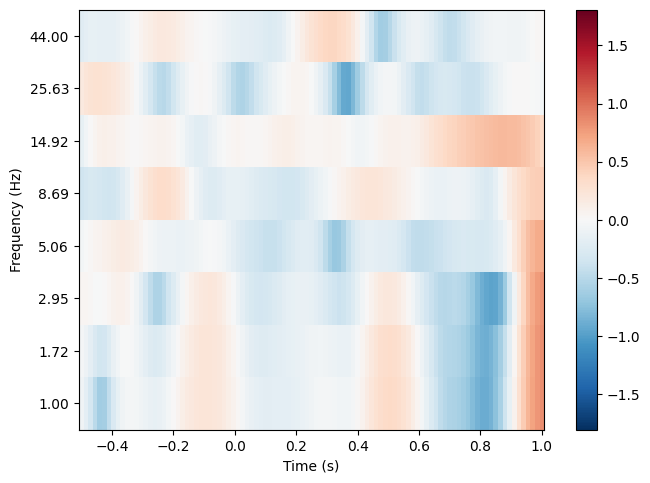

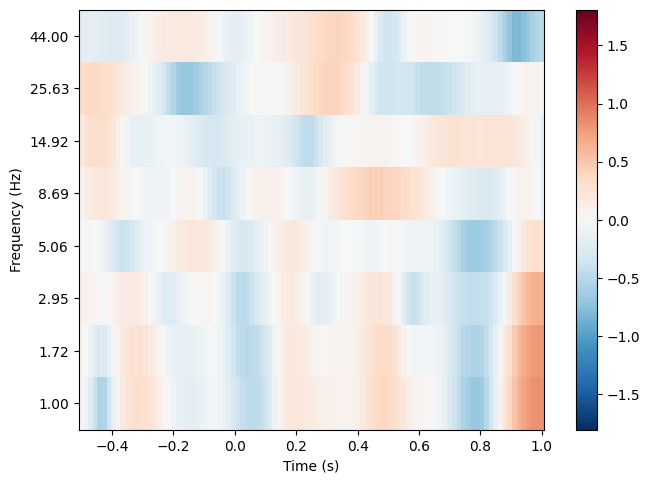

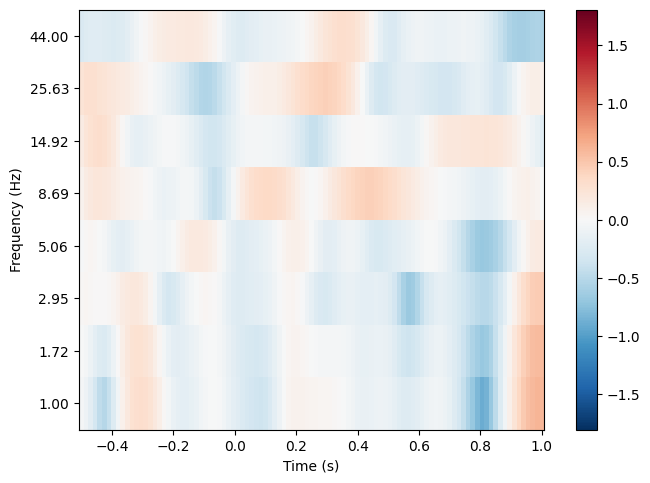

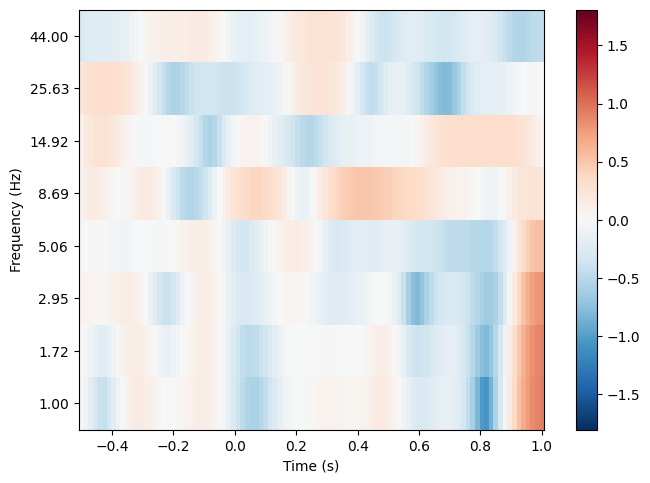

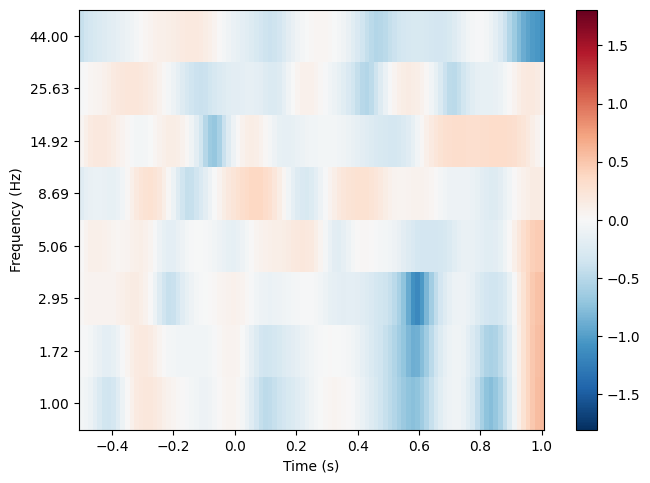

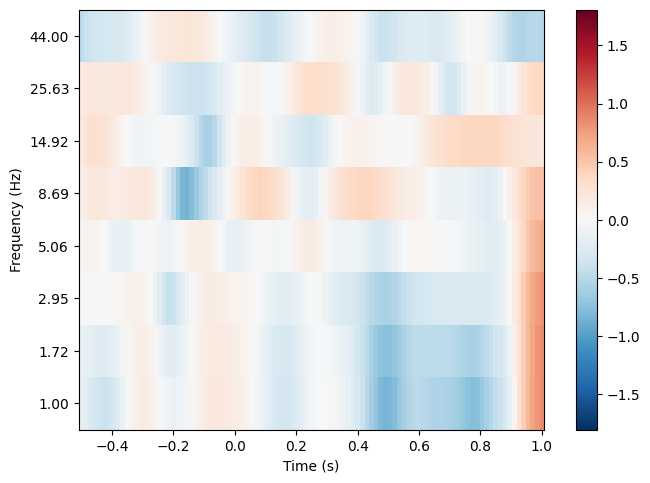

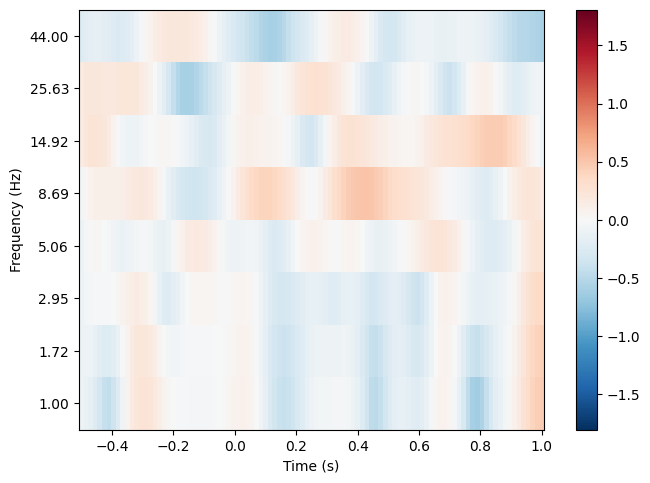

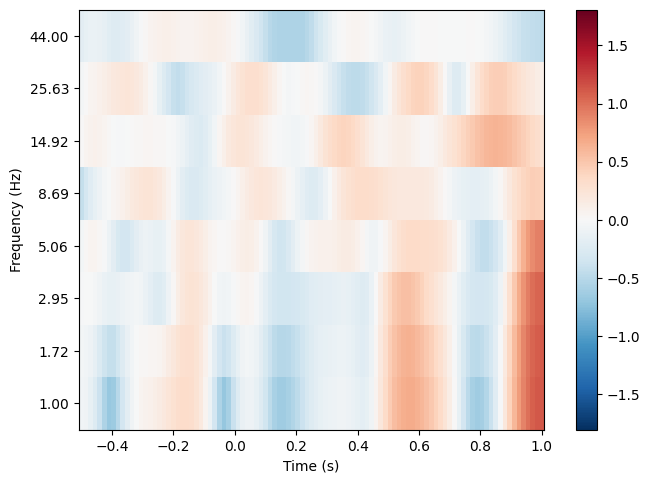

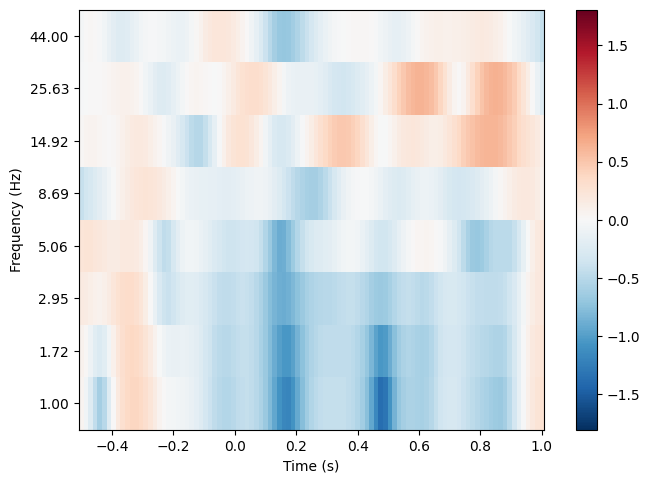

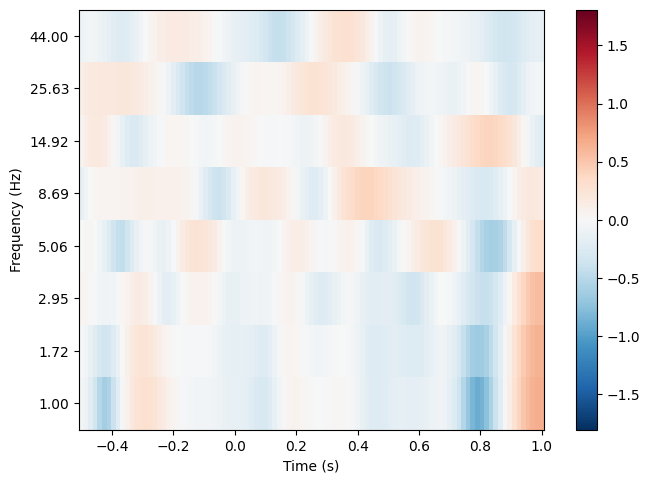

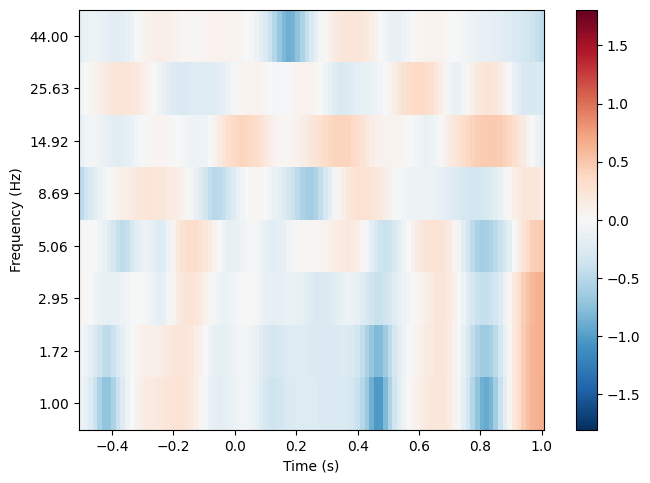

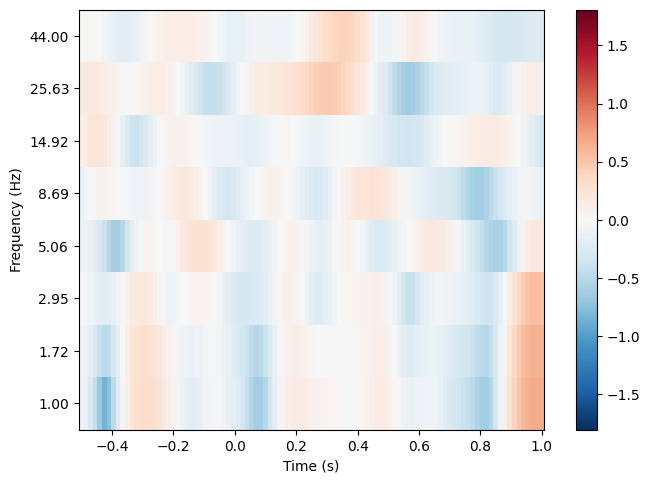

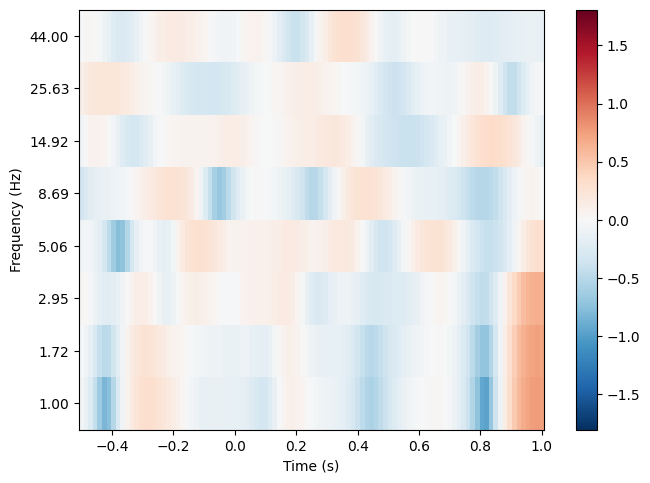

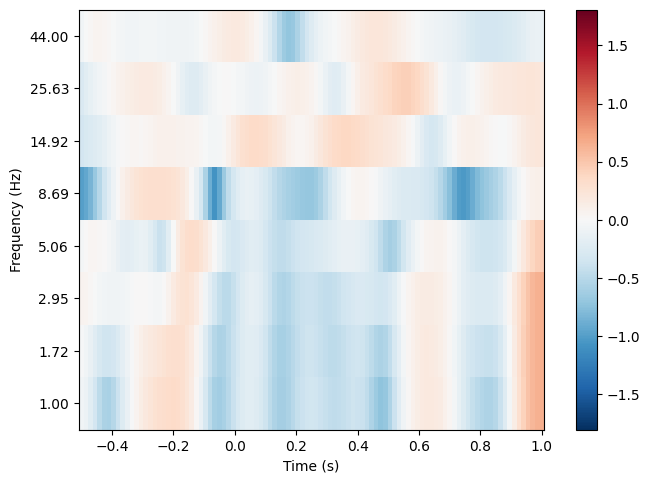

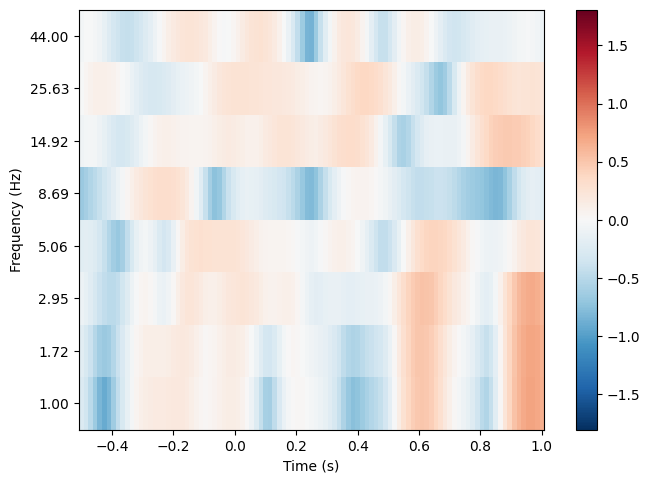

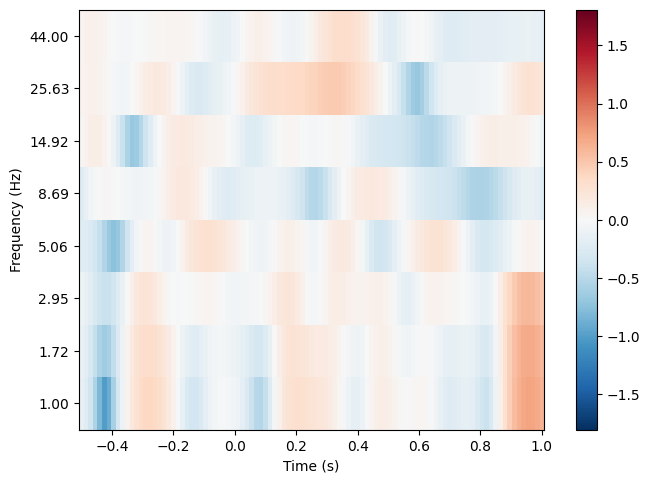

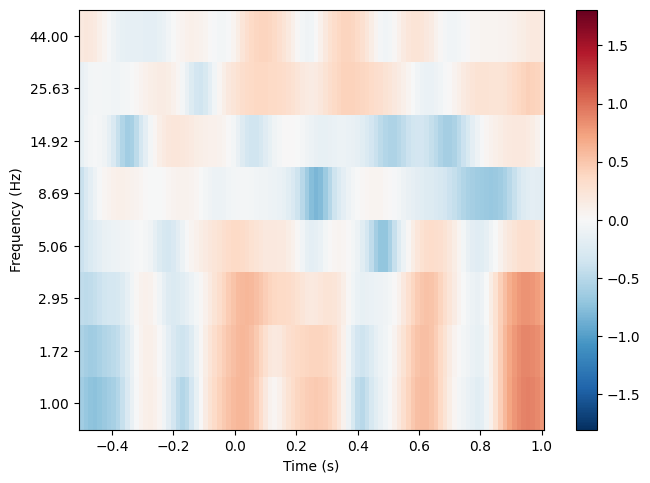

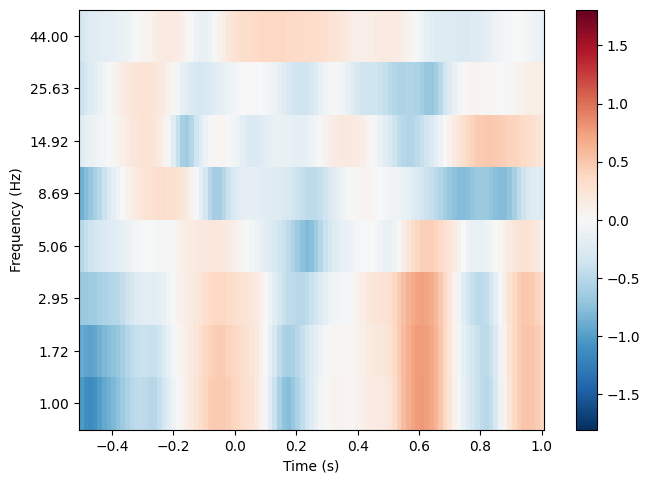

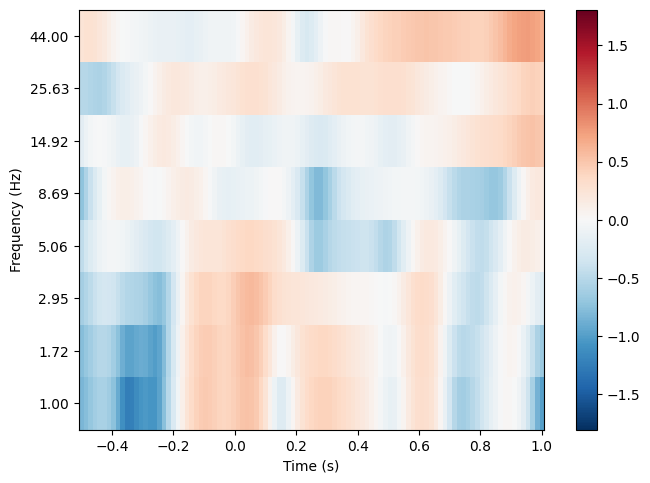

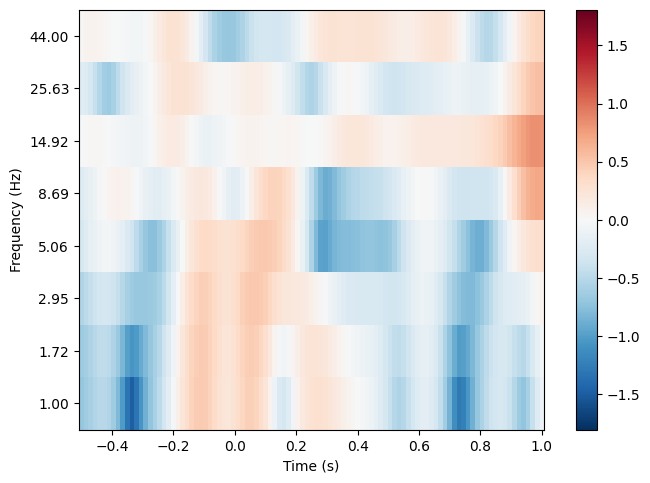

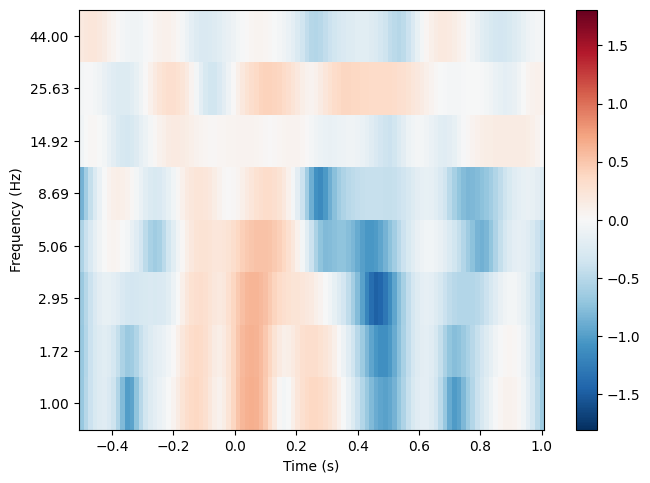

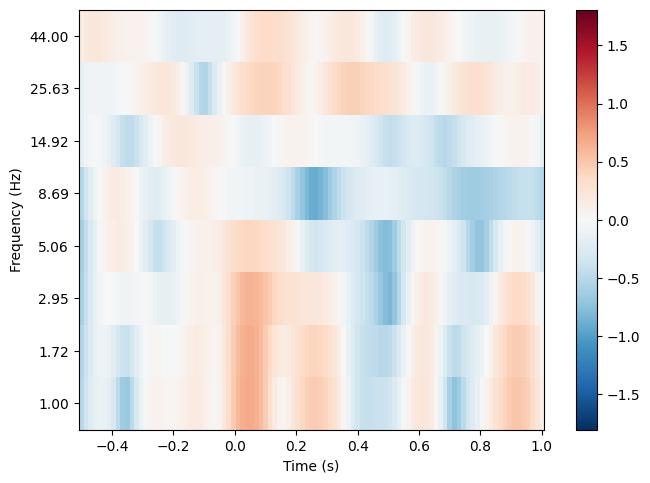

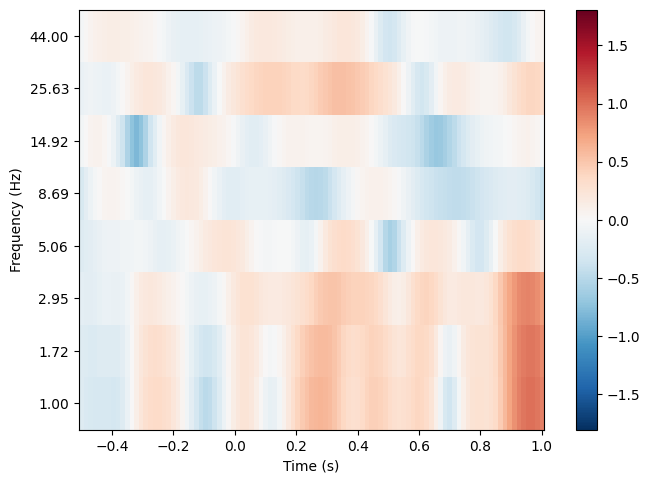

Applying baseline correction (mode: logratio)
Applying baseline correction (mode: logratio)
Applying baseline correction (mode: logratio)
Applying baseline correction (mode: logratio)
Applying baseline correction (mode: logratio)


In [84]:
power.plot_topo(baseline=(-0.5, 0), mode="logratio", title="Average power")
power.plot(picks='eeg', baseline=(-0.5, 0), mode="logratio") # так и не понял, как подписать графики для каждого электрода, но это в эту строчку 

fig, axes = plt.subplots(1, 5, figsize=(25, 15), layout="constrained")
topomap_kw = dict(
    ch_type="eeg", tmin=0.5, tmax=1.5, baseline=(-0.5, 0), mode="logratio", show=False
)
plot_dict = dict(Delta=dict(fmin=0, fmax=4), Theta=dict(fmin=4, fmax=8), Alpha=dict(fmin=8, fmax=12), Beta=dict(fmin=12, fmax=30), Gamma=dict(fmin=30, fmax=45))
for ax, (title, fmin_fmax) in zip(axes, plot_dict.items()):
    power.plot_topomap(**fmin_fmax, axes=ax, **topomap_kw)
    ax.set_title(title)

You can also create a joint plot showing both the aggregated TFR across channels and topomaps at specific times and frequencies to obtain a quick overview regarding oscillatory effects across time and space.

Applying baseline correction (mode: mean)
Applying baseline correction (mode: mean)
Applying baseline correction (mode: mean)


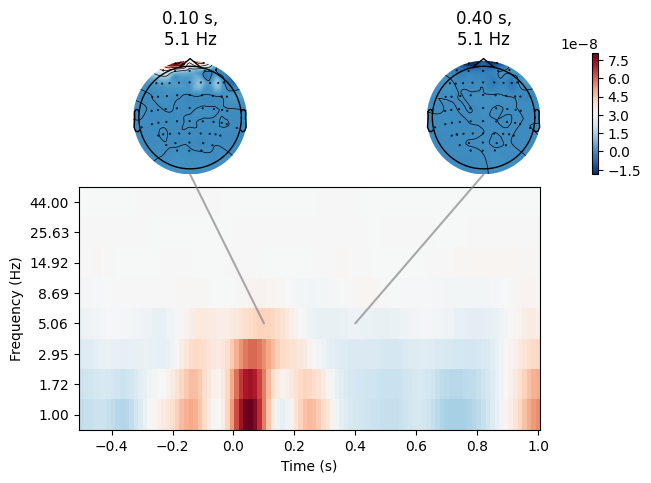

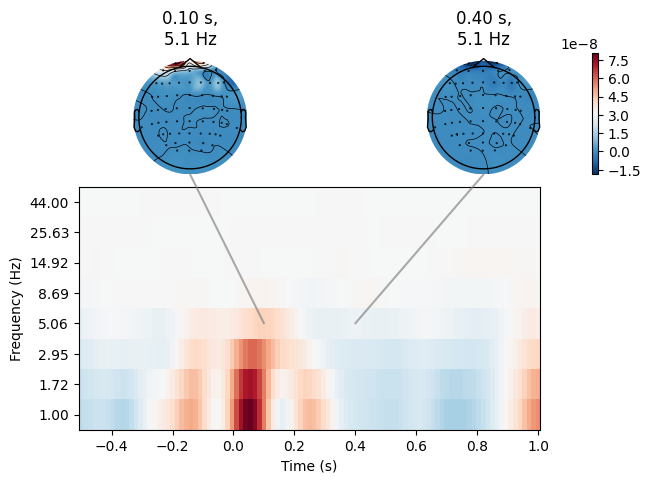

In [89]:
power.plot_joint(
    baseline=(-0.5, 0), mode="mean", tmin=-0.5, tmax=2, timefreqs=[(0.4, 5), (0.1, 5)]
)

Inspect ITC

No baseline correction applied


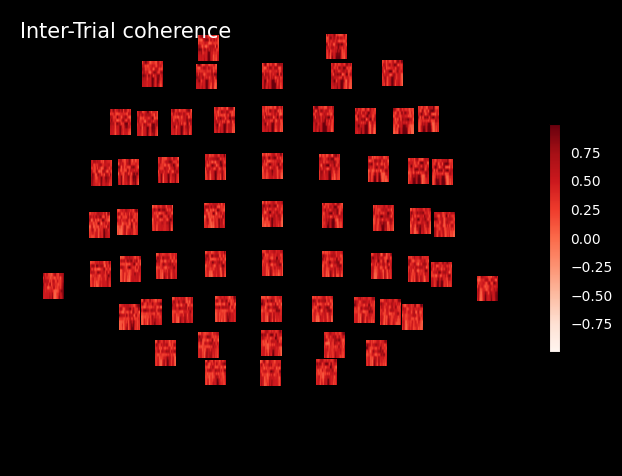

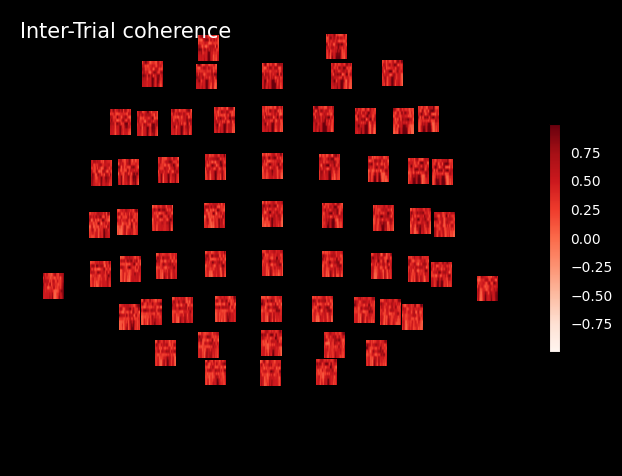

In [93]:
itc.plot_topo(title="Inter-Trial coherence", cmap="Reds")